# Coursework Template

## Setup

**Dependencies and imports**

This can take a minute...

In [2]:
%pip install swig
%pip install rldurham

  Obtaining dependency information for swig from https://files.pythonhosted.org/packages/a7/2f/7a6b14eea6d0247d3f803649f50df3cf3905714bd82f2c386fcfde9544f3/swig-4.4.1-py3-none-win_amd64.whl.metadata
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
    --------------------------------------- 0.1/2.5 MB 525.1 kB/s eta 0:00:05
    --------------------------------------- 0.1/2.5 MB 656.4 kB/s eta 0:00:04
   --- ------------------------------------ 0.2/2.5 MB 1.2 MB/s eta 0:00:03
   ---- ----------------------------------- 0.3/2.5 MB 1.5 MB/s eta 0:00:02
   ---- ----------------------------------- 0.3/2.5 MB 1.5 MB/s eta 0:00:02
   ------ --------------------------------- 0.4/2.5 MB 1.4 MB/s eta 0:00:02
   ------ --------------------------------- 0.4/2.5 MB 1.2 MB/s eta 0:00:02
   ---------- ----------------------------- 0.7/2.5 MB 1.8

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
tables 3.8.0 requires blosc2~=2.0.0, which is not installed.
tables 3.8.0 requires cython>=0.29.21, which is not installed.
numba 0.57.1 requires numpy<1.25,>=1.21, but you have numpy 1.26.4 which is incompatible.


In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""  # disable CUDA (better on Colab/NCC: choose an environment without GPU)
import torch
import rldurham as rld

## Heuristic demo

A small demo with a predefined heuristic that is suboptimal and has no notion of balance (designed for the orignal BipedalWalker environment, but should also work fine for rldurham/Walker).

In [ ]:
from gymnasium.envs.box2d.bipedal_walker import BipedalWalkerHeuristics

env = rld.make(
    "rldurham/Walker",
    # "BipedalWalker-v3",
    render_mode="human",
    # render_mode="rgb_array",
    hardcore=False,
    # hardcore=True,
)
_, obs, info = rld.seed_everything(42, env)

heuristics = BipedalWalkerHeuristics()

act = heuristics.step_heuristic(obs)
for _ in range(500):
    obs, rew, terminated, truncated, info = env.step(act)
    act = heuristics.step_heuristic(obs)
    if terminated or truncated:
        
        break
    if env.render_mode == "rgb_array":
        rld.render(env, clear=True)
env.close()

c:\Users\elixa\anaconda3\envs\myenv\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
Seed set to 42


## SAC Implementation

This is a Soft-Actor-Critic (SAC) implementation (adapted from https://github.com/seungeunrho/minimalRL/blob/master/sac.py) that does not perform very well, but is a decent starting point for the coursework. It can be outperformed by simpler methods (e.g. TD3) if they are well tuned and you are free to use any other method. Overall, the task is to make use of various ideas and principles that were covered in the lecture and/or that you find in papers to achieve the best possible performance.

In [2]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Normal
import numpy as np
import collections, random

In [3]:
class ReplayBuffer:
    def __init__(self, buffer_limit):
        self.buffer = collections.deque(maxlen=buffer_limit)

    def put(self, transition):
        self.buffer.append(transition)

    def sample(self, n):
        mini_batch = random.sample(self.buffer, n)
        s, a, r, s_p, d = zip(*mini_batch)
        return (
            torch.tensor(np.array(s),  dtype=torch.float),
            torch.tensor(np.array(a),  dtype=torch.float),
            torch.tensor(np.array(r),  dtype=torch.float).unsqueeze(1),
            torch.tensor(np.array(s_p),dtype=torch.float),
            torch.tensor(np.array(d),  dtype=torch.float).unsqueeze(1),
        )

    def size(self):
        return len(self.buffer)

In [4]:
LOG_STD_MIN, LOG_STD_MAX = -5, 2

class PolicyNet(nn.Module):
    def __init__(self, obs_dim, act_dim, lr, init_alpha, lr_alpha, target_entropy):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 256), nn.ReLU(),
            nn.Linear(256, 256),     nn.ReLU(),
            nn.Linear(256, 256),     nn.ReLU(),
        )
        self.fc_mu  = nn.Linear(256, act_dim)
        self.fc_log_std = nn.Linear(256, act_dim)

        self.optimizer = optim.Adam(self.parameters(), lr=lr)

        # Learnable temperature
        self.log_alpha = torch.tensor(np.log(init_alpha), requires_grad=True)
        self.log_alpha_optimizer = optim.Adam([self.log_alpha], lr=lr_alpha)
        self.target_entropy = target_entropy

    def forward(self, x):
        h = self.net(x)
        mu = self.fc_mu(h)
        log_std = self.fc_log_std(h).clamp(LOG_STD_MIN, LOG_STD_MAX)
        std = log_std.exp()

        dist = Normal(mu, std)
        u = dist.rsample()                                          # pre-squash sample
        action = torch.tanh(u)

        # Correct log-prob for tanh squashing
        log_prob = dist.log_prob(u) - torch.log(1 - action.pow(2) + 1e-6)
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob

    def train_net(self, q1, q2, mini_batch):
        s = mini_batch[0]
        a, log_prob = self.forward(s)

        q1_val = q1(s, a)
        q2_val = q2(s, a)
        min_q   = torch.min(q1_val, q2_val)

        # Policy loss: maximise Q - alpha * log_pi
        pi_loss = (self.log_alpha.exp().detach() * log_prob - min_q).mean()
        self.optimizer.zero_grad()
        pi_loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), 1.0)
        self.optimizer.step()

        # Alpha (temperature) loss
        alpha_loss = -(self.log_alpha.exp() * (log_prob + self.target_entropy).detach()).mean()
        self.log_alpha_optimizer.zero_grad()
        alpha_loss.backward()
        self.log_alpha_optimizer.step()

    @property
    def alpha(self):
        return self.log_alpha.exp().item()

In [5]:
class QNet(nn.Module):
    def __init__(self, obs_dim, act_dim, lr):
        super().__init__()
        # Concat s and a at input; output is a scalar Q-value
        self.net = nn.Sequential(
            nn.Linear(obs_dim + act_dim, 256), nn.ReLU(),
            nn.Linear(256, 256),               nn.ReLU(),
            nn.Linear(256, 256),               nn.ReLU(),
            nn.Linear(256, 1),
        )
        self.optimizer = optim.Adam(self.parameters(), lr=lr)

    def forward(self, s, a):
        x = torch.cat([s, a], dim=-1)
        return self.net(x)

    def train_net(self, td_target, mini_batch):
        s, a = mini_batch[0], mini_batch[1]
        loss = F.mse_loss(self.forward(s, a), td_target.detach())
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), 1.0)
        self.optimizer.step()

    def soft_update(self, net_target, tau):
        for p_tgt, p in zip(net_target.parameters(), self.parameters()):
            p_tgt.data.copy_(p_tgt.data * (1.0 - tau) + p.data * tau)

In [6]:
class Agent(nn.Module):
    def __init__(
        self,
        env,
        lr_pi=3e-4,
        lr_q=3e-4,
        lr_alpha=3e-4,
        init_alpha=0.2,           # standard SAC starting temperature
        buffer_limit=300_000,     # large buffer so good experiences aren't forgotten
        gamma=0.99,               # higher discount for long-horizon walking task
        batch_size=256,           # larger batches → more stable gradients
        tau=0.005,                # smaller tau → slower, more stable target updates
        grad_steps_per_episode=200,  # gradient updates per episode (reasonable budget)
        warmup_steps=5_000,       # pure exploration before any training
    ):
        super().__init__()
        self.env = env
        self.gamma = gamma
        self.batch_size = batch_size
        self.tau = tau
        self.grad_steps_per_episode = grad_steps_per_episode
        self.warmup_steps = warmup_steps
        self.total_steps = 0

        discrete_act, discrete_obs, act_dim, obs_dim = rld.env_info(env, print_out=True)

        # target_entropy = -|A|  (standard heuristic from SAC paper)
        target_entropy = -float(act_dim)

        self.memory = ReplayBuffer(buffer_limit)
        self.q1        = QNet(obs_dim, act_dim, lr_q)
        self.q2        = QNet(obs_dim, act_dim, lr_q)
        self.q1_target = QNet(obs_dim, act_dim, lr_q)
        self.q2_target = QNet(obs_dim, act_dim, lr_q)
        self.pi = PolicyNet(obs_dim, act_dim, lr_pi, init_alpha, lr_alpha, target_entropy)

        self.q1_target.load_state_dict(self.q1.state_dict())
        self.q2_target.load_state_dict(self.q2.state_dict())

    def action(self, s, deterministic=False):
        with torch.no_grad():
            s_t = torch.from_numpy(s).float().unsqueeze(0)
            if deterministic:
                # Use mean action (no sampling) for evaluation
                h = self.pi.net(s_t)
                a = torch.tanh(self.pi.fc_mu(h))
            else:
                a, _ = self.pi(s_t)
            return a.squeeze(0).numpy()

    def put(self, s, a, r, s_prime, done):
        self.memory.put((s, a, r, s_prime, done))

    def train(self):
        if self.memory.size() < max(self.batch_size, self.warmup_steps):
            return
        for _ in range(self.grad_steps_per_episode):
            mb = self.memory.sample(self.batch_size)
            td_target = self._calc_target(mb)
            self.q1.train_net(td_target, mb)
            self.q2.train_net(td_target, mb)
            self.pi.train_net(self.q1, self.q2, mb)
            self.q1.soft_update(self.q1_target, self.tau)
            self.q2.soft_update(self.q2_target, self.tau)

    def _calc_target(self, mini_batch):
        s, a, r, s_prime, done_mask = mini_batch
        with torch.no_grad():
            a_prime, log_prob = self.pi(s_prime)
            q1_next = self.q1_target(s_prime, a_prime)
            q2_next = self.q2_target(s_prime, a_prime)
            min_q_next = torch.min(q1_next, q2_next)
            # done_mask=0 when terminal, so next-state value is zeroed out
            target = r + self.gamma * done_mask * (min_q_next - self.pi.log_alpha.exp() * log_prob)
        return target

    def episode(self):
        done = False
        s, _ = self.env.reset()
        info = {}
        while not done:
            # Pure random exploration during warm-up for better initial coverage
            if self.total_steps < self.warmup_steps:
                a = self.env.action_space.sample()
            else:
                a = self.action(s)

            s_prime, r, terminated, truncated, info = self.env.step(a)
            done = terminated or truncated
            # FIX: store raw done flag as float (0.0 = not done → keep bootstrapping)
            self.put(s, a, r, s_prime, 0.0 if done else 1.0)
            s = s_prime
            self.total_steps += 1
        return info

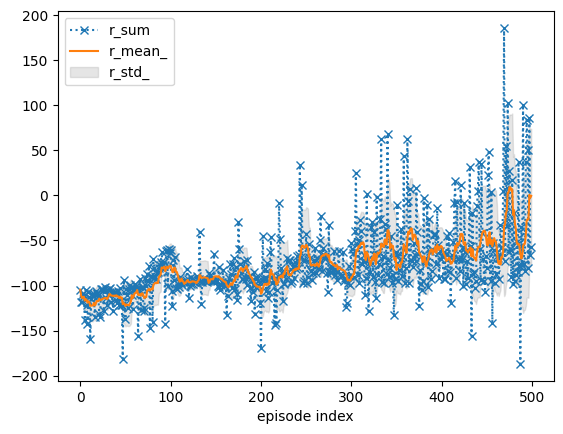

In [7]:
env = rld.make("rldurham/Walker", render_mode="rgb_array", hardcore=True)
rld.seed_everything(42, env)

env = rld.Recorder(
    env,
    smoothing=10,
    video=True,
    video_folder="videos-hardcore",
    video_prefix="zzjw57-agent-video-hardcore",  
    logs=True,
)

recorder = env
recorder.video = False
tracker = rld.InfoTracker()

# Clip large negative rewards (standard trick for Walker)
env = rld.transparent_wrapper(gym.wrappers.ClipReward)(env, min_reward=-10)

# Training loop
agent = Agent(env)
max_episodes = 500

for n_epi in range(max_episodes):
    # Record a video every 10 episodes 
    recorder.video = (n_epi + 1) % 10 == 0

    info = agent.episode()
    env.add_stats(info, ignore_existing=True)
    tracker.track(info)
    agent.train()

    if (n_epi + 1) % 10 == 0:
        print(f"Episode {n_epi+1} | alpha={agent.pi.alpha:.4f} | buffer={agent.memory.size()}")
        tracker.plot(r_mean_=True, r_std_=True, r_sum=dict(linestyle=':', marker='x'))

env.close()

env.write_log(folder="logs-hardcore", file="zzjw57-agent-log-hardcore.txt")   